# The model table: data explorer

This notebook looks at `model_table.parquet`, the table built by `01_prepare_data.ipynb`. It is the table every modelling notebook reads.

**What the table is.** One row per hour. Each row puts side by side:
- what we want to predict: solar output as a share of installed capacity (the **load factor**, column `lf`),
- the clues: the weather **as it was forecast the morning before**,
- the rival: Elia's own day-ahead forecast, kept aside as a benchmark.

**Sections**
1. What is in the table
2. The target: what we are trying to predict
3. How the weather forecast relates to output
4. The benchmarks: the scores to beat
5. Training period against test period

**One rule followed here.** Sections 2, 3 and 4 use the **training rows only**. The test period is the exam: studying it closely before the models are built would steer choices towards what works on the exam. Section 5 looks at the test period, but only at its weather and its row counts, never at its output.

**The analysis is on one area, set by `PROVINCE` (Antwerp).**
Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TABLE_FILE = Path("model_table.parquet")
PROVINCE = "Antwerp"            # the area the analysis is run on
LOCAL_TZ = "Europe/Brussels"

# chart style
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 1. What is in the table

Every column has one of four roles. Mixing them up is the most common way to build a model that looks good and is wrong.

| Role | Columns | Used how |
|---|---|---|
| Key | `datetime` (UTC, end of the hour), `region` | To identify a row |
| Target | `lf`, and `measured` (the same thing in MW) | What the model learns to predict. Never an input |
| Benchmark | `dayahead11hforecast` and its two confidence bands | Elia's forecast, in MW. Compared with our model at the end. Never an input |
| Raw features | The 16 weather columns, `monitoredcapacity`, `region` | What the model may use |
| Flag | `is_daylight`, `split` | Which rows to use, and whether a row is for training or testing |

In [2]:
table = pd.read_parquet(TABLE_FILE)
assert PROVINCE in set(table["region"]), f"{PROVINCE} is not in {TABLE_FILE}"
df = table[table["region"] == PROVINCE].sort_values("datetime").reset_index(drop=True)

WEATHER = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance",
           "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
           "temperature_2m", "dew_point_2m", "relative_humidity_2m", "surface_pressure",
           "precipitation", "wind_speed_10m", "wind_gusts_10m", "wind_direction_10m"]
LABEL = {"shortwave_radiation": "Global irradiance", "direct_radiation": "Direct irradiance", "diffuse_radiation": "Diffuse irradiance",
         "direct_normal_irradiance": "Direct normal irradiance", "cloud_cover": "Cloud cover, total", "cloud_cover_low": "Cloud cover, low",
         "cloud_cover_mid": "Cloud cover, mid", "cloud_cover_high": "Cloud cover, high", "temperature_2m": "Air temperature",
         "dew_point_2m": "Dew point", "relative_humidity_2m": "Relative humidity", "surface_pressure": "Surface pressure",
         "precipitation": "Precipitation", "wind_speed_10m": "Wind speed", "wind_gusts_10m": "Wind gusts", "wind_direction_10m": "Wind direction"}

# Elia's forecast on the same scale as the target: share of capacity
df["lf_elia"] = df["dayahead11hforecast"] / df["monitoredcapacity"]
df["local"] = df["datetime"].dt.tz_convert(LOCAL_TZ)

print(f"Areas in the table: {sorted(table['region'].unique())}")
print(f"{PROVINCE}: {len(df):,} hourly rows, {df.shape[1] - 2} columns in the file")
print(f"Period: {df['datetime'].min()}  to  {df['datetime'].max()}")
print(f"Missing values: target {df['lf'].isna().sum()}, weather {int(df[WEATHER].isna().sum().sum())}, "
      f"Elia benchmark {df['dayahead11hforecast'].isna().sum()}")

overview = df.groupby("split").agg(rows=("lf", "size"), daylight_rows=("is_daylight", "sum"),
                                   first=("datetime", "min"), last=("datetime", "max")).loc[["train", "test"]]
overview["months"] = (overview["last"] - overview["first"]) / pd.Timedelta(days=30.44)
overview

Areas in the table: ['Antwerp']
Antwerp: 22,919 hourly rows, 26 columns in the file
Period: 2024-03-15 01:00:00+00:00  to  2026-10-25 23:00:00+00:00
Missing values: target 0, weather 0, Elia benchmark 0


,rows,daylight_rows,first,last,months
split,,,,,
train,14159,7986,2024-03-15 01:00:00+00:00,2025-10-25 23:00:00+00:00,19.38
test,8760,4685,2025-10-26 00:00:00+00:00,2026-10-25 23:00:00+00:00,11.99


From here to the end of section 4, only the **training rows** are used. Most charts also keep **daylight hours** only: at night output is zero, so there is nothing to forecast and nothing to learn.

In [3]:
train = df[df["split"] == "train"]
day = train[train["is_daylight"]]
print(f"Training rows: {len(train):,}   of which daylight: {len(day):,}")

Training rows: 14,159   of which daylight: 7,986


## 2. The target: what we are trying to predict

### 2.1 Why the load factor and not megawatts

Antwerp keeps installing panels. In MW, the same sunny afternoon produces more each year, for a reason unrelated to weather. Dividing by installed capacity removes that growth, so every month is comparable. A forecast in MW is recovered by multiplying back.

The line does not only climb. Elia revises its capacity estimate from time to time, and a revision shows as a sudden step up or down: those steps are corrections to the estimate, not panels being installed or removed. Elia rescales measured output on the same dates, so the load factor stays consistent across a step, except possibly for a few days around it when the two are updated on different dates (see "Known data issues" in the README).

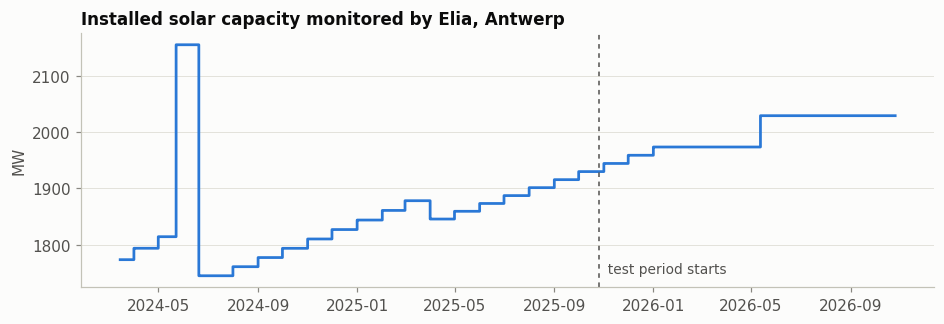

Capacity: 1,773 MW at the start, 2,029 MW at the end (+14%)


In [4]:
cap = df.set_index("datetime")["monitoredcapacity"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(cap.index, cap, color=BLUE, drawstyle="steps-post")
ax.axvline(df.loc[df["split"] == "test", "datetime"].min(), color=INK2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(df.loc[df["split"] == "test", "datetime"].min(), cap.min(), "  test period starts", color=INK2, fontsize=9, va="bottom")
ax.set_ylabel("MW"); ax.set_title(f"Installed solar capacity monitored by Elia, {PROVINCE}")
ax.grid(axis="x", visible=False)
plt.show()
print(f"Capacity: {cap.iloc[0]:,.0f} MW at the start, {cap.iloc[-1]:,.0f} MW at the end ({cap.iloc[-1] / cap.iloc[0] - 1:+.0%})")

### 2.2 How the load factor is distributed

Two things to notice. Panels almost never run near full power, because a whole province never has perfect sun on every panel at once. And many daylight hours are close to zero: early morning, late evening, and dull winter days.

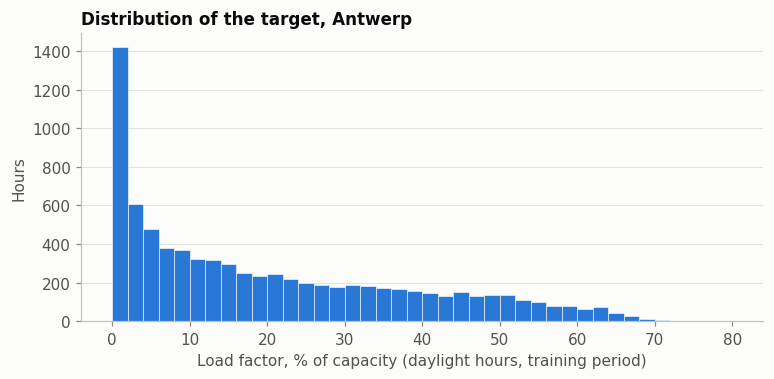

Daylight hours: mean 20.1%, median 14.6%, highest 75.7%
Daylight hours below 2% of capacity: 18%
Daylight hours above 50% of capacity: 9%


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(day["lf"] * 100, bins=np.arange(0, 82, 2), color=BLUE, edgecolor=SURFACE, linewidth=0.4)
ax.set_xlabel("Load factor, % of capacity (daylight hours, training period)"); ax.set_ylabel("Hours")
ax.set_title(f"Distribution of the target, {PROVINCE}")
ax.grid(axis="x", visible=False)
plt.show()

print(f"Daylight hours: mean {day['lf'].mean():.1%}, median {day['lf'].median():.1%}, highest {day['lf'].max():.1%}")
print(f"Daylight hours below 2% of capacity: {(day['lf'] < 0.02).mean():.0%}")
print(f"Daylight hours above 50% of capacity: {(day['lf'] > 0.50).mean():.0%}")

### 2.3 When the power is produced

Average load factor for each month and each hour of the day, in Belgian time. This is the daily and yearly rhythm the model must reproduce before weather even enters.

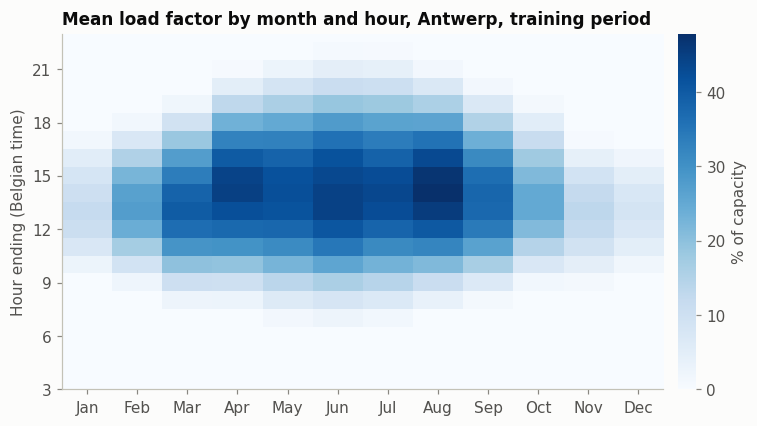

Sunniest month on average: Jun (16.7% over all hours)   Dullest: Dec (1.5%)


In [6]:
grid = train.pivot_table(index=train["local"].dt.hour, columns=train["local"].dt.month, values="lf", aggfunc="mean") * 100
grid = grid.reindex(index=range(24), columns=range(1, 13))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues", extent=[0.5, 12.5, -0.5, 23.5])
ax.set_xticks(range(1, 13), MONTHS); ax.set_yticks(range(0, 24, 3)); ax.set_ylim(3, 23)
ax.set_ylabel("Hour ending (Belgian time)")
ax.set_title(f"Mean load factor by month and hour, {PROVINCE}, training period")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("% of capacity"); cb.outline.set_visible(False)
plt.show()

energy = train.groupby(train["local"].dt.month)["lf"].mean()
print(f"Sunniest month on average: {MONTHS[energy.idxmax() - 1]} ({energy.max():.1%} over all hours)   "
      f"Dullest: {MONTHS[energy.idxmin() - 1]} ({energy.min():.1%})")

## 3. How the weather forecast relates to output

### 3.1 Forecast sunlight against output

Each point is one daylight hour. If the forecast were perfect and all panels identical, the points would form a thin line. The spread around the line is what the model has to explain, and part of it cannot be explained at all, because the forecast itself is sometimes wrong.

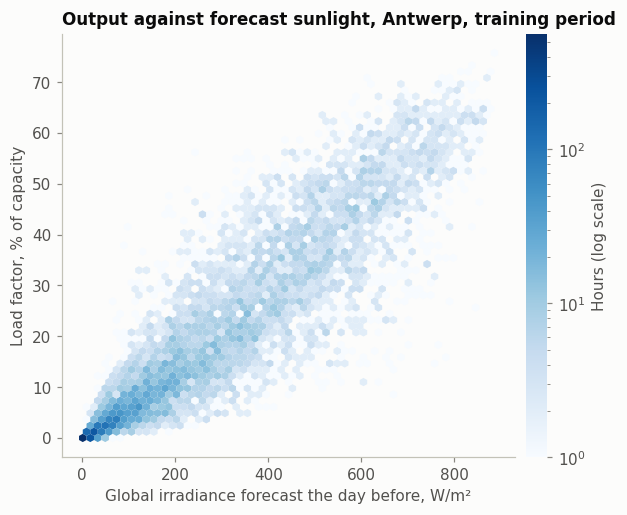

Correlation between forecast sunlight and load factor (daylight): 0.908


In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5))
hb = ax.hexbin(day["shortwave_radiation"], day["lf"] * 100, gridsize=55, cmap="Blues", mincnt=1, bins="log", linewidths=0)
ax.set_xlabel("Global irradiance forecast the day before, W/m²")
ax.set_ylabel("Load factor, % of capacity")
ax.set_title(f"Output against forecast sunlight, {PROVINCE}, training period")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax, pad=0.02); cb.set_label("Hours (log scale)"); cb.outline.set_visible(False)
plt.show()
print(f"Correlation between forecast sunlight and load factor (daylight): {day['shortwave_radiation'].corr(day['lf']):.3f}")

### 3.2 Which weather variables carry information?

Correlation of each forecast variable with the load factor, in daylight hours. This is a first look, not a model: the variables overlap a lot (sunlight already reflects cloud), and correlation only sees straight-line relations. Wind direction is left out because it is a circular variable.

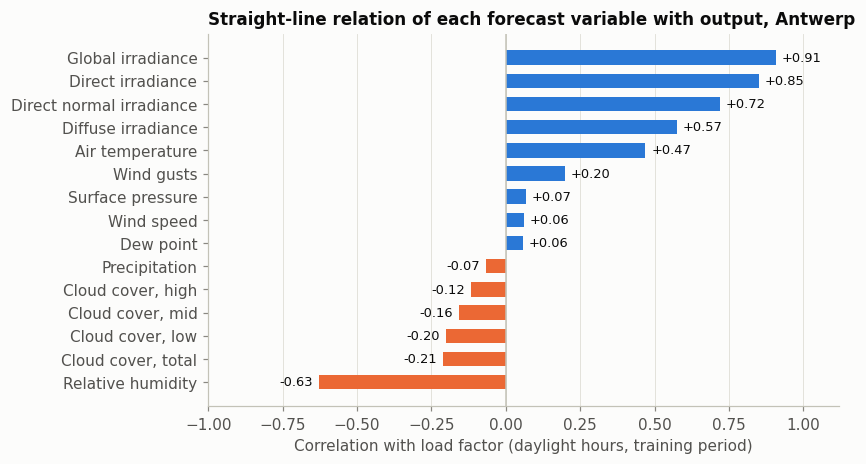

In [8]:
feats = [c for c in WEATHER if c != "wind_direction_10m"]
corr = day[feats].corrwith(day["lf"]).sort_values()
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.barh([LABEL[c] for c in corr.index], corr.values, color=[BLUE if v >= 0 else ORANGE for v in corr.values], height=0.62)
ax.axvline(0, color=AXIS, linewidth=1)
for y, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK)
ax.set_xlim(-1, 1.12)
ax.set_xlabel("Correlation with load factor (daylight hours, training period)")
ax.set_title(f"Straight-line relation of each forecast variable with output, {PROVINCE}")
ax.grid(axis="y", visible=False)
plt.show()

### 3.3 The cloud forecast, with the sun held fixed

To see cloud on its own, the sun's position has to be held roughly fixed: the months from May to August, around midday (hours ending 12:00 to 15:00 Belgian time). Within that window, the bars show average output for each band of **forecast** cloud cover. The thin lines show the spread: how much output varies among hours with the same cloud forecast.

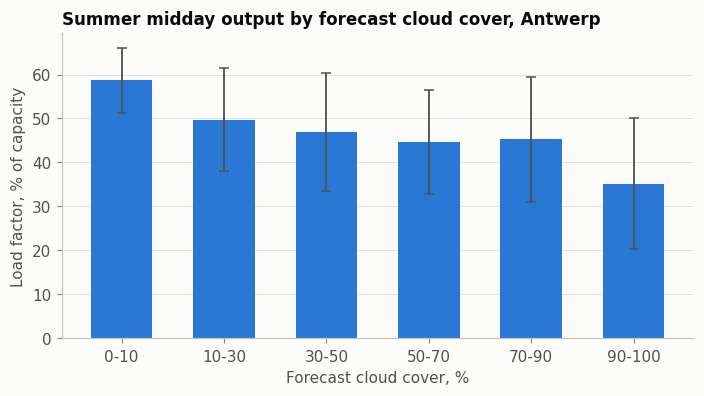

,mean load factor %,spread (std) %,hours
cloud_band,,,
0-10,58.66,7.42,130
10-30,49.70,11.73,93
30-50,46.87,13.40,99
50-70,44.60,11.83,96
70-90,45.28,14.21,97
90-100,35.15,14.94,469


In [9]:
mid = train[train["local"].dt.month.isin([5, 6, 7, 8]) & train["local"].dt.hour.isin([12, 13, 14, 15])].copy()
mid["cloud_band"] = pd.cut(mid["cloud_cover"], bins=[-1, 10, 30, 50, 70, 90, 100], labels=["0-10", "10-30", "30-50", "50-70", "70-90", "90-100"])
g = mid.groupby("cloud_band", observed=True)["lf"].agg(["mean", "std", "size"])

fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE, width=0.6)
ax.errorbar(g.index.astype(str), g["mean"] * 100, yerr=g["std"] * 100, fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3)
ax.set_xlabel("Forecast cloud cover, %"); ax.set_ylabel("Load factor, % of capacity")
ax.set_title(f"Summer midday output by forecast cloud cover, {PROVINCE}")
ax.grid(axis="x", visible=False)
plt.show()

out = (g.assign(mean=g["mean"] * 100, std=g["std"] * 100)
        .rename(columns={"mean": "mean load factor %", "std": "spread (std) %", "size": "hours"}))
out

Reading the chart: output falls as the cloud forecast rises, as expected. The spread matters as much as the average. A wide spread under a given forecast means that forecast leaves a lot undecided, which is where a day-ahead model will make its largest errors.

### 3.4 Temperature: is the heat effect visible?

Panels lose a little efficiency as they heat up. If that shows in this data, output per unit of sunlight should fall as the forecast temperature rises. The chart takes bright hours only (forecast irradiance above 500 W/m²) and shows output per unit of forecast sunlight, by forecast temperature.

Read the result as it comes. A clear downward slope would mean temperature gives the model something sunlight does not. A flat or irregular line means the effect is too small to see at this level of detail, or is hidden by other things that change with temperature (the season, the height of the sun, errors in the sunlight forecast). In that case temperature may still help a model, but it should not be expected to matter much.

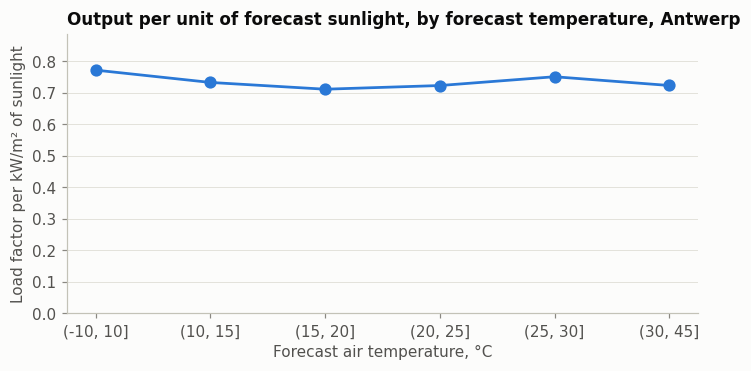

Lowest band value 0.71, highest 0.77: a range of 9%


,load factor per kW/m²,hours
temp_band,,
"(-10, 10]",0.77,34
"(10, 15]",0.73,162
"(15, 20]",0.71,467
"(20, 25]",0.72,602
"(25, 30]",0.75,257
"(30, 45]",0.72,63


In [10]:
bright = day[day["shortwave_radiation"] > 500].copy()
bright["yield"] = bright["lf"] / (bright["shortwave_radiation"] / 1000)
bright["temp_band"] = pd.cut(bright["temperature_2m"], bins=[-10, 10, 15, 20, 25, 30, 45])
t = bright.groupby("temp_band", observed=True)["yield"].agg(["mean", "size"])
t = t[t["size"] >= 20]                 # bands with very few hours are too noisy to show

fig, ax = plt.subplots(figsize=(7.4, 3.3))
ax.plot(t.index.astype(str), t["mean"], color=BLUE, marker="o", markersize=7)
ax.set_xlabel("Forecast air temperature, °C"); ax.set_ylabel("Load factor per kW/m² of sunlight")
ax.set_title(f"Output per unit of forecast sunlight, by forecast temperature, {PROVINCE}")
ax.set_ylim(0, t["mean"].max() * 1.15)
ax.grid(axis="x", visible=False)
plt.show()
print(f"Lowest band value {t['mean'].min():.2f}, highest {t['mean'].max():.2f}: a range of {(t['mean'].max() / t['mean'].min() - 1):.0%}")
t.rename(columns={"mean": "load factor per kW/m²", "size": "hours"})

## 4. The benchmarks: the scores to beat

A model is only worth something if it beats what the client could already do. Two alternatives:

- **Elia's day-ahead forecast**, published free at 11:00 the day before. The professional standard.
- **A naive rule**: assume tomorrow will repeat a day we have already seen.

**How error is measured.** For each daylight hour, take the gap between forecast and actual load factor, in points of capacity. The **average miss** is the mean of those gaps, ignoring their sign (mean absolute error). The **bias** keeps the sign: positive means the forecast is too high on average.

**Which naive rule is honest?** "Same hour yesterday" sounds natural, but for tomorrow afternoon it needs this afternoon's output, which has not happened yet at 11:00. The honest version uses the same hour **two days before delivery**, which is always known. Both are shown, so the cost of being honest is visible. The team has not yet fixed the exact rule.

These scores are on the **training period**. The scores on the test period belong in the evaluation notebook, next to the models.

In [11]:
def lagged(hours):
    # The load factor a given number of hours earlier, matched on the clock so a gap cannot shift it
    past = train[["datetime", "lf"]].rename(columns={"lf": "v"})
    past["datetime"] = past["datetime"] + pd.Timedelta(hours=hours)
    return train[["datetime"]].merge(past, on="datetime", how="left")["v"].to_numpy()

bench = train[["datetime", "local", "is_daylight", "lf", "lf_elia", "cloud_cover"]].copy()
bench["naive_2d"] = lagged(48)
bench["naive_1d"] = lagged(24)
bench = bench[bench["is_daylight"]].dropna(subset=["lf_elia", "naive_2d", "naive_1d"])     # the same hours for all three

def score(col):
    err = (bench[col] - bench["lf"]) * 100
    return {"average miss (MAE), points": err.abs().mean(), "RMSE, points": np.sqrt((err ** 2).mean()), "bias, points": err.mean()}

results = pd.DataFrame({
    "Naive: same hour two days before (known at 11:00)": score("naive_2d"),
    "Naive: same hour the day before (not fully known at 11:00)": score("naive_1d"),
    "Elia day-ahead forecast (11:00)": score("lf_elia"),
}).T
print(f"Scored on {len(bench):,} daylight hours of the training period, {bench['datetime'].min():%d %b %Y} to {bench['datetime'].max():%d %b %Y}")
results

Scored on 7,962 daylight hours of the training period, 17 Mar 2024 to 25 Oct 2025


,"average miss (MAE), points","RMSE, points","bias, points"
Naive: same hour two days before (known at 11:00),8.43,13.02,-0.00
Naive: same hour the day before (not fully known at 11:00),8.02,12.52,0.01
Elia day-ahead forecast (11:00),3.70,5.68,0.57


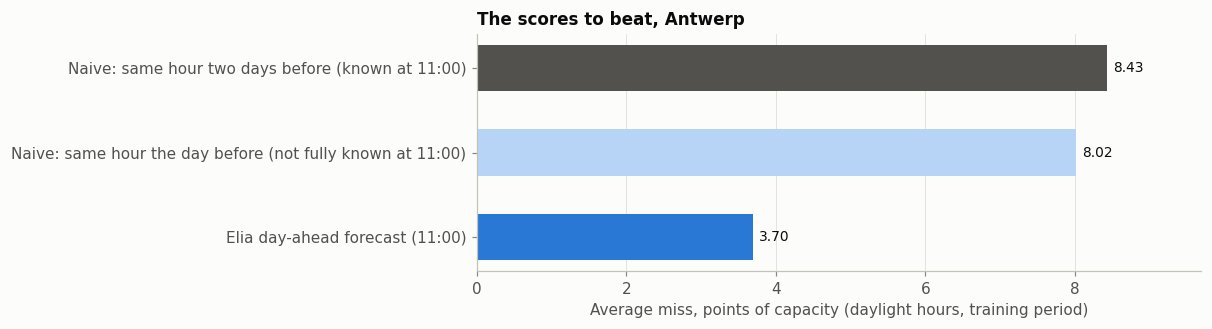

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
r = results["average miss (MAE), points"].iloc[::-1]
ax.barh(r.index, r.values, color=[BLUE, BLUE_LIGHT, INK2], height=0.55)
for y, v in enumerate(r.values):
    ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, r.max() * 1.15)
ax.set_xlabel("Average miss, points of capacity (daylight hours, training period)")
ax.set_title(f"The scores to beat, {PROVINCE}")
ax.grid(axis="y", visible=False)
plt.show()

### 4.1 Where Elia's forecast is weakest

If Elia's error is concentrated in certain conditions, that is where a new model has the most room to add value. The first chart splits Elia's average miss by month, the second by the cloud cover in **our** weather forecast.

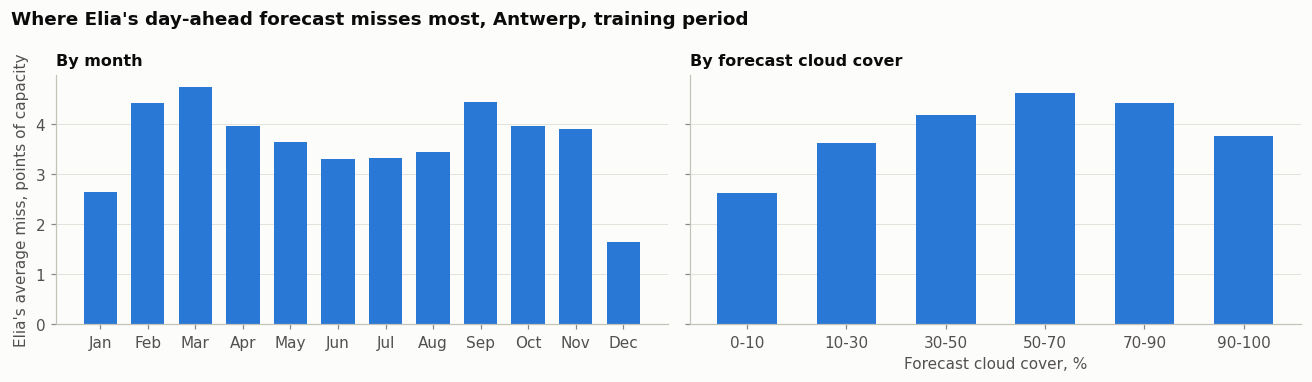

,"average miss, points","bias, points",hours
cloud_band,,,
0-10,2.63,0.79,1417
10-30,3.63,1.18,800
30-50,4.19,0.86,673
50-70,4.63,0.88,571
70-90,4.43,0.12,609
90-100,3.76,0.33,3892


In [13]:
bench["elia_err"] = (bench["lf_elia"] - bench["lf"]) * 100
by_month = bench.groupby(bench["local"].dt.month)["elia_err"].agg(mae=lambda s: s.abs().mean(), bias="mean", hours="size")
bench["cloud_band"] = pd.cut(bench["cloud_cover"], bins=[-1, 10, 30, 50, 70, 90, 100], labels=["0-10", "10-30", "30-50", "50-70", "70-90", "90-100"])
by_cloud = bench.groupby("cloud_band", observed=True)["elia_err"].agg(mae=lambda s: s.abs().mean(), bias="mean", hours="size")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax1.bar(by_month.index, by_month["mae"], color=BLUE, width=0.7)
ax1.set_xticks(range(1, 13), MONTHS); ax1.set_ylabel("Elia's average miss, points of capacity")
ax1.set_title("By month", fontsize=10.5); ax1.grid(axis="x", visible=False)
ax2.bar(by_cloud.index.astype(str), by_cloud["mae"], color=BLUE, width=0.6)
ax2.set_xlabel("Forecast cloud cover, %"); ax2.set_title("By forecast cloud cover", fontsize=10.5); ax2.grid(axis="x", visible=False)
fig.suptitle(f"Where Elia's day-ahead forecast misses most, {PROVINCE}, training period", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()
by_cloud.rename(columns={"mae": "average miss, points", "bias": "bias, points"})

A caution on the monthly chart: summer errors are larger in points of capacity simply because output is larger in summer. A big bar in June does not mean Elia is worse in June relative to what is produced.

## 5. Training period against test period

A model can only be trusted on the test period if that period resembles what it learned from. Two checks, neither of which looks at test output.

### 5.1 How many hours of each month

The training period is not a whole number of years, so some months appear more often than others. Months that appear only once in training are the ones the model knows least well.

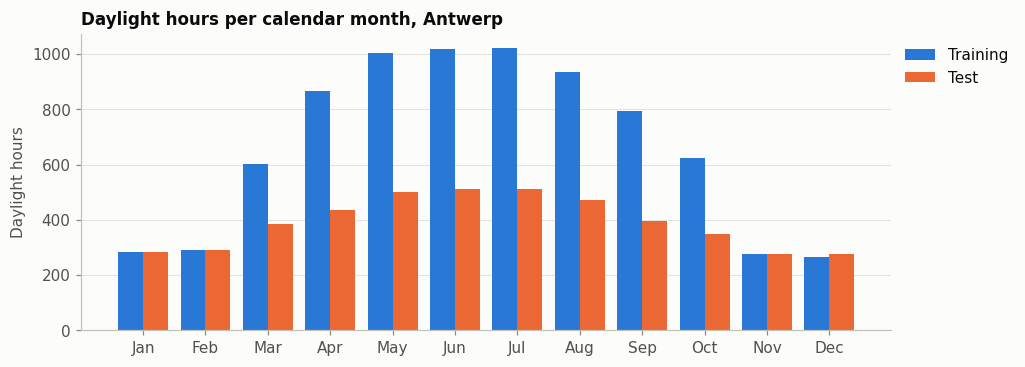

How many times each calendar month appears in the training period (a month counts even if incomplete):
  Jan 1   Feb 1   Mar 2   Apr 2   May 2   Jun 2   Jul 2   Aug 2   Sep 2   Oct 2   Nov 1   Dec 1


In [14]:
dl = df[df["is_daylight"]]
counts = dl.groupby([dl["local"].dt.month, "split"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0)[["train", "test"]]

fig, ax = plt.subplots(figsize=(9.5, 3.5))
x = np.arange(1, 13)
ax.bar(x - 0.2, counts["train"], width=0.4, color=BLUE, label="Training")
ax.bar(x + 0.2, counts["test"], width=0.4, color=ORANGE, label="Test")
ax.set_xticks(x, MONTHS); ax.set_ylabel("Daylight hours")
ax.set_title(f"Daylight hours per calendar month, {PROVINCE}")
ax.grid(axis="x", visible=False); ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

seen = train.assign(y=train["local"].dt.year, m=train["local"].dt.month).drop_duplicates(["y", "m"]).groupby("m").size().reindex(range(1, 13), fill_value=0)
print("How many times each calendar month appears in the training period (a month counts even if incomplete):")
print("  " + "   ".join(f"{m} {int(seen[i + 1])}" for i, m in enumerate(MONTHS)))

### 5.2 Was the weather forecast similar?

To compare like with like, the test year is set against the **twelve months just before it**, so both windows contain every season once. Only weather forecasts are compared, not output.

A difference can be real weather (one year sunnier than the other) or a change in the weather model: ECMWF upgraded its forecasting system on 12 May 2026, inside the test year. A large gap is a reason to check the model's errors on that variable, not proof of a problem.

In [15]:
test = df[df["split"] == "test"]
test_start = test["datetime"].min()
prior = train[train["datetime"] >= test_start - pd.DateOffset(years=1)]
print(f"Year before the test period: {prior['datetime'].min():%d %b %Y} to {prior['datetime'].max():%d %b %Y} ({len(prior):,} hours)")
print(f"Test period:                 {test['datetime'].min():%d %b %Y} to {test['datetime'].max():%d %b %Y} ({len(test):,} hours)")

sun = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance"]
rows = {}
for c in feats:
    a = prior.loc[prior["is_daylight"], c] if c in sun or c.startswith("cloud") else prior[c]
    b = test.loc[test["is_daylight"], c] if c in sun or c.startswith("cloud") else test[c]
    rows[LABEL[c]] = {"year before": a.mean(), "test year": b.mean(),
                      "change %": (b.mean() / a.mean() - 1) * 100 if c not in ("temperature_2m", "dew_point_2m") else np.nan,
                      "change, in units": b.mean() - a.mean()}
shift = pd.DataFrame(rows).T
shift.sort_values("change %", key=abs, ascending=False)

Year before the test period: 26 Oct 2024 to 25 Oct 2025 (8,760 hours)
Test period:                 26 Oct 2025 to 25 Oct 2026 (8,760 hours)


,year before,test year,change %,"change, in units"
"Cloud cover, high",32.76,40.44,23.43,7.68
Precipitation,0.07,0.08,16.66,0.01
"Cloud cover, low",33.84,29.26,-13.53,-4.58
"Cloud cover, mid",25.73,28.28,9.94,2.56
Direct irradiance,165.62,170.94,3.21,5.32
Direct normal irradiance,325.02,333.96,2.75,8.94
Relative humidity,74.68,76.26,2.12,1.58
Global irradiance,267.05,271.14,1.53,4.09
Wind speed,11.23,11.37,1.31,0.15
Diffuse irradiance,101.43,100.20,-1.21,-1.23


## What to take from this

The cell below gathers the main numbers.

In [16]:
print(f"Area: {PROVINCE}   Table: {len(df):,} hours, {df['datetime'].min():%d %b %Y} to {df['datetime'].max():%d %b %Y}")
print(f"Training: {len(train):,} hours ({len(day):,} daylight).   Test: {len(test):,} hours ({int(test['is_daylight'].sum()):,} daylight)")
print(f"Target: daylight load factor averages {day['lf'].mean():.1%} and peaks at {day['lf'].max():.1%}")
print(f"Forecast sunlight explains much of it: correlation {day['shortwave_radiation'].corr(day['lf']):.2f}")
m = results["average miss (MAE), points"]
print(f"Scores to beat on the training period (average miss, points of capacity): "
      f"naive two days before {m.iloc[0]:.2f}, Elia {m.iloc[2]:.2f}")
print(f"Using yesterday's output for the naive rule would score {m.iloc[1]:.2f}, but it is not fully known at 11:00")
print(f"Elia misses most under forecast cloud cover of {by_cloud['mae'].idxmax()}%: {by_cloud['mae'].max():.2f} points")
print(f"Calendar months seen only once in training: {', '.join(MONTHS[i] for i in range(12) if seen[i + 1] == 1) or 'none'}")
big = shift["change %"].abs().sort_values(ascending=False).head(3)
print(f"Largest weather differences between the test year and the year before: "
      + ", ".join(f"{k} ({shift.loc[k, 'change %']:+.0f}%)" for k in big.index))

Area: Antwerp   Table: 22,919 hours, 15 Mar 2024 to 25 Oct 2026
Training: 14,159 hours (7,986 daylight).   Test: 8,760 hours (4,685 daylight)
Target: daylight load factor averages 20.1% and peaks at 75.7%
Forecast sunlight explains much of it: correlation 0.91
Scores to beat on the training period (average miss, points of capacity): naive two days before 8.43, Elia 3.70
Using yesterday's output for the naive rule would score 8.02, but it is not fully known at 11:00
Elia misses most under forecast cloud cover of 50-70%: 4.63 points
Calendar months seen only once in training: Jan, Feb, Nov, Dec
Largest weather differences between the test year and the year before: Cloud cover, high (+23%), Precipitation (+17%), Cloud cover, low (-14%)


**Reminders**
- The weather columns are forecasts made the morning before delivery, not the weather that happened. See `explore_weather_dayahead.ipynb`.
- `dayahead11hforecast` and its bands are the benchmark. They must never be model inputs.
- Nothing in this notebook changes the table. It only reads it.